# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [1]:
from typing import List, Tuple, Dict
from io import StringIO

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [2]:
import numpy as np

In [3]:
from Bio import SeqIO


def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> len(seqs) > 0
        True
    """
    fasta_dict = {record.id: str(record.seq) for record in SeqIO.parse(filename, "fasta")}
    return fasta_dict


In [4]:
# Global variables for directionality
END = 0
DIAG = 1
UP = 2
LEFT = 3

In [5]:
def cal_score(matrix, seq1, seq2, i, j, match, mismatch, gap):
    '''Calculate score for position (i,j) in scoring matrix, also record move to trace back

    Args:
        matrix (numpy array): scoring matrix
        seq1 (str): sequence 1
        seq2 (str): sequence 2
        i (int): current row number
        j (int): current column number

    Returns:
        score in position (i,j)
        move to trace back: 0-END, 1-DIAG, 2-UP, 3-LEFT


    FROM PROJECT 5
    Pseudocode:
        Compare sequence 1 and 2
        Define the match/mismatch/gap scores
            Note: negatives scores will be converted to zeroes

        Calculate scores based on upper-left, up, and left neighbors:
            diag_score = upper-left + (match or mismatch)
            up_score = up + gap
            left_score = left + gap
        score = max(0, diag_score, up_score, left_score)
        traceback = maximum direction or end

        figure out the best score
        maximum of 0, diag_score, up_score, left_score

        figure out traceback direction
        if the best score is 0
            end
        else:
            if the best score != 0
                up diagonal or left
        Return the traceback direction and score
    '''


    if seq1[i - 1] == seq2[j - 1]:
        diag_score = matrix[i - 1][j - 1] + match
    else:
        diag_score = matrix[i - 1][j - 1] + mismatch

    # calculate the gap scores
    up_score = matrix[i - 1][j] + gap
    left_score = matrix[i][j - 1] + gap

    # Calculate the max of the cell, 0 ensures no negatives
    best_score = max(0, diag_score, up_score, left_score)

    # Establish positions; tie-breaker priority: diag --> up --> left
    if best_score == 0:
        direction = END
    elif best_score == diag_score:
        direction = DIAG
    elif best_score == up_score:
        direction = UP
    else:
        direction = LEFT


    return best_score, direction


In [6]:
import numpy as np
def prev_smith_waterman(seq1, seq2, match=2.0, mismatch=-1.0, gap=-1.0):
    '''Smith-Waterman algorithm for local alignment

    Args:
        seq1 (str): input seq 1
        seq2 (str): input seq 2
        match: default = +2.0
        mismatch: default = -1.0
        gap: default = -1.0

    Returns:
        aligned_seq1 (str)
        aligned_seq2 (str)
        score_matrix (numpy array): scoring matrix

    Pseudocode:
    Initialize scoring matrix H with zeros
    For i from 1 to m:
        For j from 1 to n:
            H[i][j] = max {
                0
                H[i-1][j-1] + match/mismatch score
                H[i-1][j] + gap penalty
                H[i][j-1] + gap penalty
                }
    Find the highest score in  H text and its position
    Return the optimal local alignment

    # NOTE: THIS IS PASTED FROM PROJECT 5, RENAMED, AND RETURN SIGNATURE MODIFIED.

    '''

    # initialize sequence lengths m and n
    m, n = len(seq1), len(seq2)

    # initialize the base maximum score and positions for i and j
    highest_score = 0
    highest_position = (0,0)

    # initialize scoring matrix H with zeros using numpy, add one because S-W uses an extra row/column
    score_matrix = np.zeros((m+1, n+1), dtype=int)

    # filling out scoring matrix H
    for i in range(1, m + 1):
        for j in range(1, n + 1):

            # call cal_score on our variables
            best_score, direction = cal_score(score_matrix, seq1, seq2, i, j, match, mismatch, gap)

            # assign the best score into the matrix
            score_matrix[i][j] = best_score

            # Check scoring matrix H against the maximum score and positioning
            if best_score > highest_score:
                highest_score = best_score
                highest_position = (i, j)


    return highest_score

In [7]:
import math
def smith_waterman(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0

    pseudocode:
    call previous smith waterman algorithm from project 5 to get:
    self score of sequence 1
    self score of sequence 2
    highest score comparison between sequence 1 and 2

    Normalization step:
    if the self scores are not 0
        S(i,j) = SW(i,j) / sqrt(SW(i,i) x SW(j,j))
    else if there is a zero in the denominator
        only return a 0.0 so the program doesnt break

    """

    # raw local alignment score of (i,i) by calling previous SW
    self_scorei = prev_smith_waterman(sequence1, sequence1, match_score, mismatch_penalty, gap_penalty)

    # raw local alignment score of (j,j) by calling previous SW
    self_scorej = prev_smith_waterman(sequence2, sequence2, match_score, mismatch_penalty, gap_penalty)

    # maximum alignment score of (i,j) by calling previous SW
    sequence_comparison = prev_smith_waterman(sequence1, sequence2, match_score, mismatch_penalty, gap_penalty)

    # Make sure the denominator isn't 0
    if self_scorei != 0 and self_scorej != 0:
        # calculate normalized score by dividing the max (i,j) by sqrt of (i,i)x(jj)
        norm_score = sequence_comparison / (math.sqrt(self_scorei * self_scorej))

    else:
        # if the denominator is 0, just break and return 0.0 for no similarities
        return 0.0

    return norm_score

In [8]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        >>> len(ids)  # Number of sequences
        19

    Normalized scores need to be converted to distance in BDM():
    D(i,j) = 1 - S(i,j)

    pseudocode:
    extract sequence names by thieir index
    initialize a distance matrix of zeros
    for i and j,
        call smith_waterman for the normalized scores
        convert to distance
        store distances at i and j (distance i,j == distance j,i

    """
    # extract the sequence names from the fasta dict using keys
    sequence_names = list(sequences.keys())

    # initialize distanze matrix with zeros
    distance_matrix = np.zeros((len(sequences), len(sequences)))

    # for index i in the range of first index to the last index:
    for i in range(0, len(sequences)-1):
        # for index j offset from index i:
        for j in range(i+1, len(sequences)):

            # retrieve sequences i and j using their IDs
            sequence_i = sequences[sequence_names[i]]
            sequence_j = sequences[sequence_names[j]]

            # Call smith waterman to hold the normalized scores
            score_conv = smith_waterman(sequence_i, sequence_j)

            # Convert normalized scores to distances and store in the matrix
            distance_scores = 1-score_conv
            distance_matrix[i, j] = distance_scores
            distance_matrix[j, i] = distance_scores


    return distance_matrix, sequence_names

In [9]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> tree = neighbor_joining(mat, ids)
        >>> tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        >>> tree.count(",")  # Number of separators in tree
        18



    """
    # preserve tree structure throughout iteration and construction by storing labels and sequences
    tree_branches = {label: label for label in labels}
    labels = list(labels)
    return neighbor_join_recursion(distance_matrix, labels, tree_branches)



In [10]:
import numpy as np
def neighbor_join_recursion(distance_matrix: np.ndarray, labels, tree_branches):
    """
    Helper function for neighbor-joining recursion.

    :return:

    Pseudocode and logic:
    Calculate row totals
    Determine n for the matrix

    If n > 3:
        Calculate D* for non duplicate pairs
            # Calculate D* based on D*(i,j) = (n-2) * D(i,j) - TD(i) - TD(j)
        Find the pair with the minimum D*
        Update the best pair positions

        Calculate the branch length differences for internal node based on delta
            # delta(i,j) = (TD(i) - TD(j)) / n-2

        Create new internal node; record connections.

        Calculate distances from the new node to all remaining nodes.

        Update the matrix by removing the columns and rows and adding one for new node
        repeat until 3 nodes left

    If n = 3:
        The final joining:
            L(a)=1/2(D(a,b)+D(a,c)−D(b,c))
            L(b)=1/2(D(a,b)+D(b,c)−D(a,c))
            L(c)=1/2(D(a,c)+D(b,c)−D(a,b))


    """
    # Calculate each row total
    row_totals = np.sum(distance_matrix, axis=1)

    # Calculate n for matrix
    current_nodes = distance_matrix.shape[0]


    # Based on the walkthrough, the iterations will go until n=3
    if current_nodes > 3:

        # We don't want to hit the minimum by hardcoding a limit
        minimum_dstar = float('inf')

        # initialize the best pair to 0 first
        best_pair = (0,0)

        # iterate up through the last but stop before so it doesn't go out of bounds
        for i in range(current_nodes-1):

            # Start after index i to avoid duplicates
            for j in range(i+1, current_nodes):

                # Calculate D* based on D*(i,j) = (n-2) * D(i,j) - TD(i) - TD(j)
                d_star = (current_nodes - 2) * distance_matrix[i][j] - row_totals[i] - row_totals[j]

                # if D* is less than the minimum (it is), set D* as the minimum and store in i,j
                if d_star < minimum_dstar:
                    minimum_dstar = d_star
                    best_pair = (i,j)

        # unpack the pair
        i, j = best_pair

        # calculate delta based on delta(i,j) = (TD(i) - TD(j)) / n-2
        delta = (row_totals[i] - row_totals[j]) / (current_nodes - 2)

        # Calculate each branch length L(i) = (D(i,j) + delta(i,j)) / 2, L(j) = D(i,j) - L(i)
        branch_length_i = (distance_matrix[i][j] + delta) / 2
        branch_length_j = distance_matrix[i][j] - branch_length_i


        # Initialize variable to hold the distance from the new node to every other node with k
        new_distances = []

        # For k in the range of the remaining nodes
        for k in range(current_nodes):

            # if k is not the same as i and j, calculate the new distances and append
            if k != i and k != j:
                new_distance = (distance_matrix[i][k] + distance_matrix[j][k] - distance_matrix[i][j]) / 2
                new_distances.append(new_distance)


        # Remove the joined nodes
        smaller_matrix = np.delete(np.delete(distance_matrix, [i, j], axis=0),[i, j],axis=1)
        # Add the new row
        smaller_matrix = np.insert(smaller_matrix, smaller_matrix.shape[0], new_distances, axis=0)
        # Add the new column
        smaller_matrix = np.insert(smaller_matrix, smaller_matrix.shape[1], [*new_distances, 0], axis=1)


        # preserve the branches that are getting combined and removed
        joined_node_i = labels[i]
        joined_node_j = labels[j]

        # Create an internal node counter to update the nodes we create after joining two
        new_node_names = []
        for index, name in enumerate(labels):
            if index != i and index != j:
                new_node_names.append(name)
        internal_node_count = 1

        for name in labels:
            if name.startswith("U") and name[1:].isdigit():
                internal_node_count = max(internal_node_count, int(name[1:]) + 1)
        updated_names = f"U{internal_node_count}"
        new_node_names.append(updated_names)


        # Preserve the order and identity of the branches that get combined and removed to add into the tree
        tree_branches[updated_names] = (
            f"({tree_branches[joined_node_i]}:{branch_length_i},"f"{tree_branches[joined_node_j]}:{branch_length_j})"
        )

        # delete them after storing
        del tree_branches[joined_node_i]
        del tree_branches[joined_node_j]

        # update matrix labels
        labels = new_node_names
        return neighbor_join_recursion(smaller_matrix, labels, tree_branches)


    # If the remaining nodes = 3, we want to start the final join
    elif current_nodes == 3:
        # Get the distance between each of the remaining 3 nodes
        ab_distance = distance_matrix[0][1]
        ac_distance = distance_matrix[0][2]
        bc_distance = distance_matrix[1][2]

        # Calculate branch lengths
        # L(a)=1/2(D(a,b)+D(a,c)−D(b,c))
        branch_length_a = (1/2) * (ab_distance + ac_distance - bc_distance)
        # L(b)=1/2(D(a,b)+D(b,c)−D(a,c))
        branch_length_b = (1/2) * (ab_distance + bc_distance - ac_distance)
         # L(c)=1/2(D(a,c)+D(b,c)−D(a,b))
        branch_length_c = (1/2) * (ac_distance + bc_distance - ab_distance)

        final_tree = (
        f"({tree_branches[labels[0]]}:{branch_length_a},"
        f"{tree_branches[labels[1]]}:{branch_length_b},"
        f"{tree_branches[labels[2]]}:{branch_length_c});"
    )
        return final_tree



In [11]:
# Testing provided via ChatGPT

import numpy as np

test_matrix_3 = np.array([
    [0.0, 5.0, 9.0],
    [5.0, 0.0, 10.0],
    [9.0, 10.0, 0.0]
])

test_labels_3 = ["A", "B", "C"]

tree_branches = {label: label for label in test_labels_3}

tree_3 = neighbor_join_recursion(
    test_matrix_3,
    test_labels_3,
    tree_branches
)

print("Three-sequence tree:", tree_3)

test_matrix_4 = np.array([
    [0.0,  5.0,  9.0,  9.0],
    [5.0,  0.0, 10.0, 10.0],
    [9.0, 10.0,  0.0,  8.0],
    [9.0, 10.0,  8.0,  0.0]
])

test_labels_4 = ["A", "B", "C", "D"]

tree_branches = {label: label for label in test_labels_4}

tree_4 = neighbor_join_recursion(
    test_matrix_4,
    test_labels_4,
    tree_branches
)

print("Four-sequence tree:", tree_4)

test_matrix_5 = np.array([
    [0.0,  5.0,  9.0,  9.0,  8.0],
    [5.0,  0.0, 10.0, 10.0,  9.0],
    [9.0, 10.0,  0.0,  8.0,  7.0],
    [9.0, 10.0,  8.0,  0.0,  6.0],
    [8.0,  9.0,  7.0,  6.0,  0.0]
])

test_labels_5 = ["A", "B", "C", "D", "E"]
tree_branches = {label: label for label in test_labels_5}

tree_5 = neighbor_join_recursion(
    test_matrix_5,
    test_labels_5,
    tree_branches
)

print("Five-sequence tree:", tree_5)



tree_4 = neighbor_joining(test_matrix_4, test_labels_4)
print(tree_4)

tree_5 = neighbor_joining(test_matrix_5, test_labels_5)
print(tree_5)


Three-sequence tree: (A:2.0,B:3.0,C:7.0);
Four-sequence tree: (C:4.0,D:4.0,(A:2.0,B:3.0):3.0);
Five-sequence tree: (D:3.5,E:2.5,(C:4.0,(A:2.0,B:3.0):3.0):0.5);
(C:4.0,D:4.0,(A:2.0,B:3.0):3.0);
(D:3.5,E:2.5,(C:4.0,(A:2.0,B:3.0):3.0):0.5);


In [12]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


In [13]:
import os

print("Current working directory:", os.getcwd())
print("File exists:", os.path.exists("data/lafayette_SARS_RT.fasta"))

Current working directory: /Users/a14074/PycharmProjects/BINF6250/project06
File exists: True


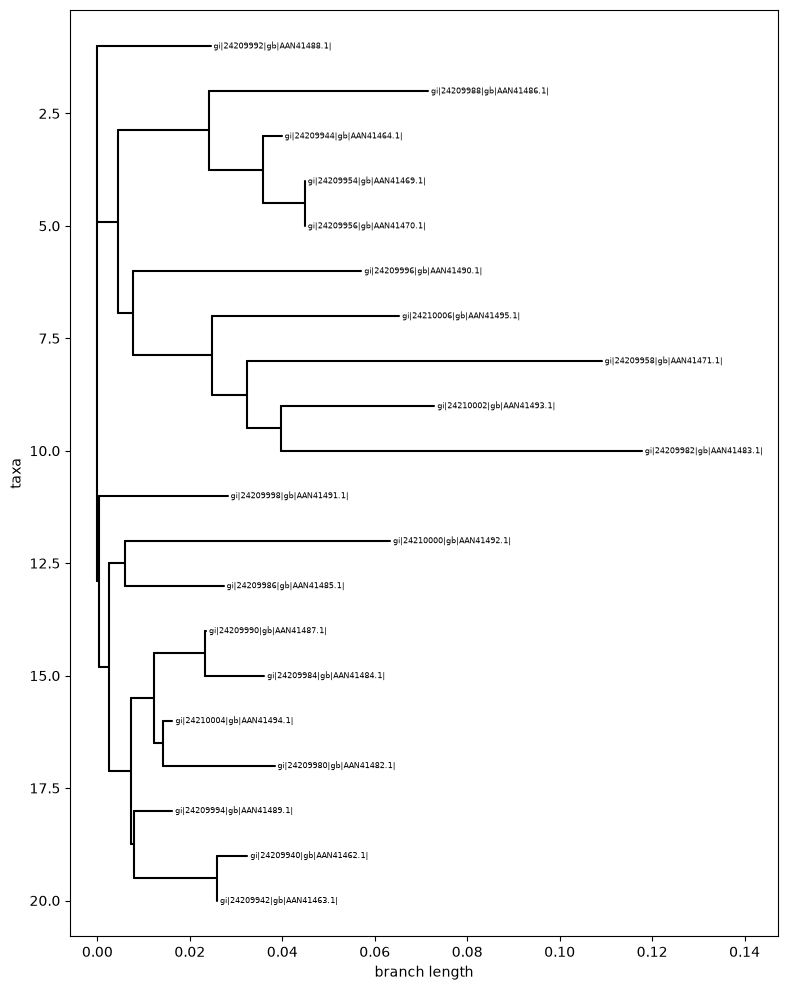

In [14]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("data/lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)